# Atividade_2

## Objetivos

- Treinar uma regressão linear com 8 variáveis de entrada em PyTorch, usando `nn.Linear(8, 1)`, `nn.MSELoss` e `optim.SGD`.
- Dividir os dados em treino, validação e teste (70/15/15).
- Avaliar o modelo no teste (RMSE em dólares) e comparar com um baseline que sempre prevê o preço médio do treino.
- Interpretar os pesos aprendidos.

O modelo agora tem 8 entradas:

$$\hat{y} = w_0 + w_1 x_1 + \dots + w_8 x_8$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

Cada linha é um quarteirão (*block group*) da Califórnia (censo de 1990). A saída `y` é o valor mediano das casas do quarteirão, em centenas de milhares de dólares.

Variáveis de entrada:

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana do quarteirão (dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude |
| `Longitude` | longitude |

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # y em centenas de milhares de dólares

print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### Análise dos dados

In [3]:
df = X.copy()
df['MedHouseVal'] = y
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


O preço (`MedHouseVal`) tem máximo em 5,0 (500 mil dólares): os valores acima disso foram cortados nesse valor. Além disso, `AveRooms`, `AveBedrms`, `Population` e `AveOccup` têm máximos muito maiores que a média (valores extremos).

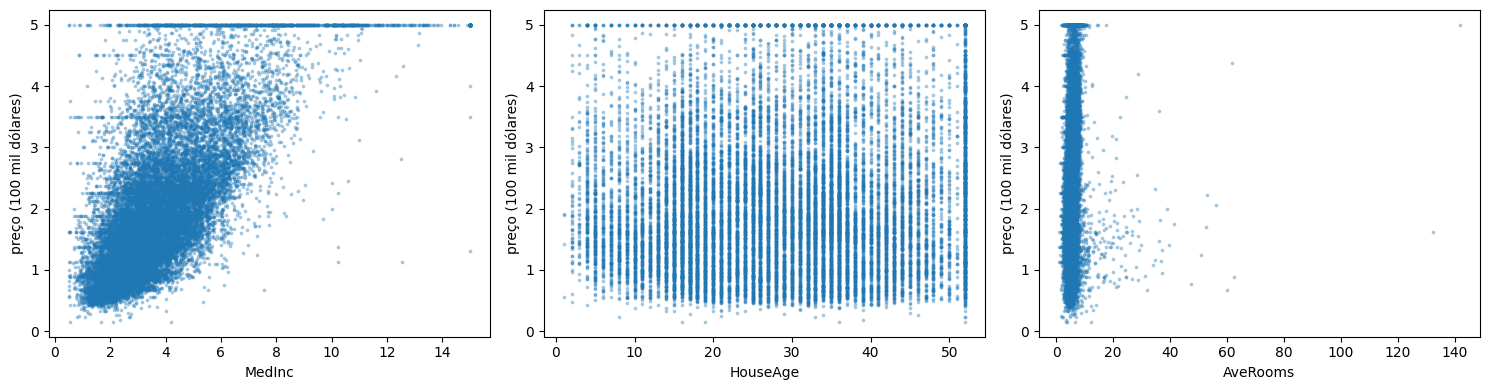

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, ['MedInc', 'HouseAge', 'AveRooms']):
    ax.scatter(df[col], df['MedHouseVal'], s=3, alpha=0.3)
    ax.set_xlabel(col)
    ax.set_ylabel('preço (100 mil dólares)')
plt.tight_layout()
plt.show()

A renda mediana (`MedInc`) tem relação crescente clara com o preço. Já `HouseAge` mostra pouca relação, e em `AveRooms` os valores extremos atrapalham a visualização.

### Treino, validação e teste

Divisão 70/15/15 com `random_state` fixo. O teste só é usado no final.

In [5]:
x_raw = X.to_numpy()                 # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)  # (20640, 1)

# 70% treino, 30% restante
x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)

# 30% restante -> metade validação, metade teste (15% e 15%)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.5, random_state=42)

print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape, ' teste:', x_test_raw.shape)

treino: (14448, 8)  validação: (3096, 8)  teste: (3096, 8)


### Padronização

Média e desvio padrão são calculados só no treino (`fit`) e aplicados em validação e teste (`transform`), para não vazar informação.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

def para_tensor(a):
    return torch.from_numpy(a).float()

x_train = para_tensor(x_scaler.transform(x_train_raw))
y_train = para_tensor(y_scaler.transform(y_train_raw))
x_val = para_tensor(x_scaler.transform(x_val_raw))
y_val = para_tensor(y_scaler.transform(y_val_raw))
x_test = para_tensor(x_scaler.transform(x_test_raw))
y_test = para_tensor(y_scaler.transform(y_test_raw))

print('x_train:', x_train.shape, ' y_train:', y_train.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])


## Modelo

`nn.Linear(8, 1)`: `model.weight` tem shape (1, 8), um peso por variável, e `model.bias` é o $w_0$.

In [7]:
torch.manual_seed(1234)
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)

weight: torch.Size([1, 8])  bias: torch.Size([1])


## Treinamento

Mesmo esquema do 2.6: `nn.MSELoss`, `optim.SGD` e as funções `train_epoch` e `validate_epoch`. Cada época usa todo o conjunto de treino.

In [8]:
lr = 0.1
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [10]:
n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[50/300], Train Loss: 0.406007, Val Loss: 0.417940
Epoch[100/300], Train Loss: 0.393754, Val Loss: 0.406560
Epoch[150/300], Train Loss: 0.391298, Val Loss: 0.404330
Epoch[200/300], Train Loss: 0.390795, Val Loss: 0.403884
Epoch[250/300], Train Loss: 0.390687, Val Loss: 0.403787
Epoch[300/300], Train Loss: 0.390663, Val Loss: 0.403760


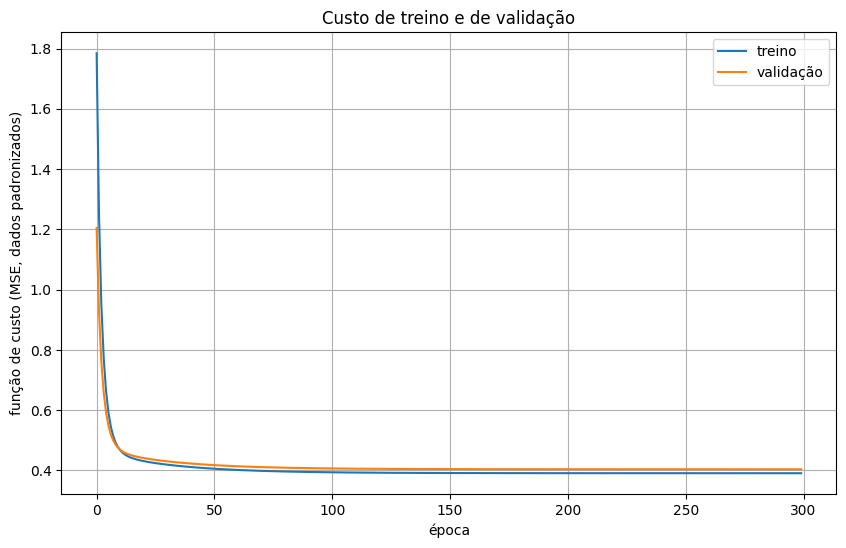

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem juntas e ficam próximas, sem sinal de overfitting. O modelo é simples (só 9 parâmetros), então o custo estabiliza num valor alto: ele é limitado pelo próprio modelo linear, não pelo treino.

## Avaliação

### RMSE no teste, em dólares, e baseline

O baseline sempre prevê o preço médio do treino. Se o modelo não ganhar do baseline, ele não aprendeu nada útil.

In [12]:
model.eval()
with torch.no_grad():
    y_test_pred = model(x_test)

# volta para a escala original (centenas de milhares de dólares) e converte para dólares
y_test_pred_raw = y_scaler.inverse_transform(y_test_pred.numpy())
fator = 100_000

rmse_modelo = np.sqrt(np.mean((y_test_pred_raw - y_test_raw) ** 2)) * fator

# baseline: sempre o preço médio do treino
media_treino = y_train_raw.mean()
rmse_baseline = np.sqrt(np.mean((media_treino - y_test_raw) ** 2)) * fator

print(f'RMSE do modelo no teste:   US$ {rmse_modelo:,.0f}')
print(f'RMSE do baseline (média):  US$ {rmse_baseline:,.0f}')
print(f'preço médio no teste:      US$ {y_test_raw.mean() * fator:,.0f}')

RMSE do modelo no teste:   US$ 72,117
RMSE do baseline (média):  US$ 114,992
preço médio no teste:      US$ 206,596


R2 no teste: 0.607


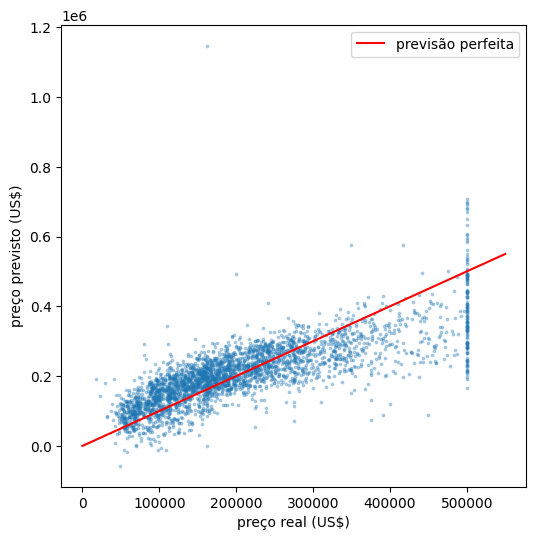

In [13]:
# R2 no teste: 1 - (erro do modelo / erro do baseline)
r2 = 1 - (rmse_modelo / rmse_baseline) ** 2
print(f'R2 no teste: {r2:.3f}')

plt.figure(figsize=(6, 6))
plt.scatter(y_test_raw * fator, y_test_pred_raw * fator, s=3, alpha=0.3)
lim = [0, 5.5 * fator]
plt.plot(lim, lim, 'r-', label='previsão perfeita')
plt.xlabel('preço real (US$)')
plt.ylabel('preço previsto (US$)')
plt.legend()
plt.show()

### Pesos aprendidos

Os pesos estão na escala padronizada (efeito de 1 desvio padrão da variável, em desvios padrão do preço).

Latitude     -0.763859
Longitude    -0.742118
AveRooms     -0.259479
AveOccup     -0.036152
Population   -0.000419
HouseAge      0.106505
AveBedrms     0.300880
MedInc        0.734834
dtype: float32
bias (w0): 1.2722484399319e-08


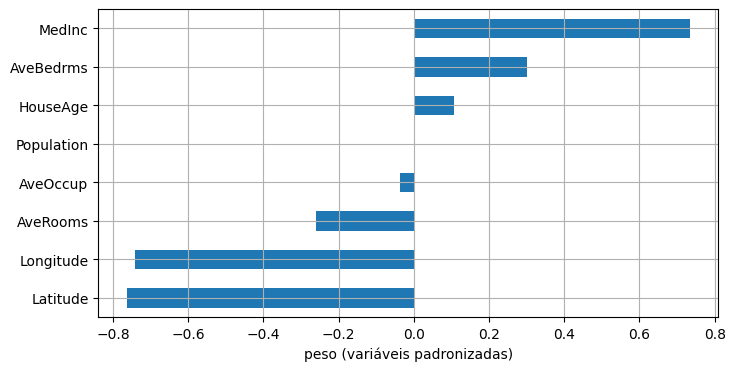

In [14]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns)
pesos = pesos.sort_values()
print(pesos)
print('bias (w0):', model.bias.item())

pesos.plot(kind='barh', figsize=(8, 4))
plt.xlabel('peso (variáveis padronizadas)')
plt.grid(True)
plt.show()

In [15]:
# conferência: solução analítica (equação normal) com os dados de treino
X_bias = torch.cat([torch.ones(x_train.shape[0], 1), x_train], dim=1)
w_opt = torch.linalg.inv(X_bias.t().mm(X_bias)).mm(X_bias.t()).mm(y_train)
print('analítico (w0, w1..w8):', w_opt.ravel().numpy().round(3))
print('treinado  (w0, w1..w8):', np.r_[model.bias.item(), model.weight.detach().numpy().ravel()].round(3))

analítico (w0, w1..w8): [-0.     0.734  0.106 -0.259  0.301 -0.001 -0.036 -0.772 -0.75 ]
treinado  (w0, w1..w8): [ 0.     0.735  0.107 -0.259  0.301 -0.    -0.036 -0.764 -0.742]


**Quais variáveis mais aumentam e quais mais diminuem o preço previsto?**

Quem mais aumenta o preço é `MedInc` (renda mediana), com o maior peso positivo. `AveBedrms` e `HouseAge` também têm peso positivo, bem menor. Quem mais diminui são `Latitude` e `Longitude`, com pesos negativos grandes: quanto mais ao norte e mais a leste, menor o preço previsto (as áreas mais caras ficam no litoral, no sul e na região da baía). `AveRooms` também tem peso negativo, o que é estranho, e acontece porque `AveRooms` e `AveBedrms` são correlacionadas entre si. `Population` e `AveOccup` têm peso perto de zero.

**Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?**

Cada peso mede quanto a saída muda quando a variável aumenta 1 unidade. Sem padronizar, as unidades são muito diferentes (`Population` vai a milhares, `Latitude` varia poucos graus), então um peso pequeno pode ser de uma variável com escala enorme e um peso grande de uma variável com escala pequena. Padronizando, todas ficam com média 0 e desvio padrão 1, e cada peso passa a ser o efeito de variar 1 desvio padrão da variável. Assim os pesos ficam na mesma escala e podem ser comparados.

## Conclusão

O modelo ganha do baseline: o RMSE no teste fica bem abaixo do RMSE de sempre prever a média, e o R² é de cerca de 0,6. Mas o erro ainda é grande, da ordem de dezenas de milhares de dólares para um preço médio de cerca de 200 mil, e o gráfico de previsão × real mostra que o modelo erra mais nas casas mais caras e não passa de 500 mil por causa do corte nos dados. Para um primeiro modelo simples é razoável, mas não é bom o suficiente para uso real.

Para melhorar, eu tentaria:
- usar modelos não lineares, como uma rede neural com camadas escondidas ou árvores (o preço depende da localização de forma não linear);
- criar variáveis novas, como a distância até o litoral ou às grandes cidades, ou usar latitude e longitude de forma mais inteligente;
- tratar os valores extremos (`AveRooms`, `AveOccup`) e o corte do preço em 500 mil;